In [2]:
#librerias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Cargar DataSet (Wine)

In [3]:
from sklearn.datasets import load_wine

In [6]:
#cargar desde scikit-learn
wine = load_wine(as_frame=True)
df: pd.DataFrame = wine.frame.copy()

### EDA/limpieza

In [7]:
#info
print('Info dataset')
df.info()

Info dataset
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  tar

In [8]:
print(f'Nulos\n {df.isnull().sum()}')
print(f'Duplicados: {df.duplicated().sum()}')

Nulos
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
Duplicados: 0


In [9]:
desc: pd.DataFrame = df.describe().transpose()
desc["rango"] = desc["max"] - desc["min"]
display(desc[["mean", "std", "min", "max", "rango"]])

,mean,std,min,max,rango
alcohol,13.000618,0.811827,11.03,14.83,3.80
malic_acid,2.336348,1.117146,0.74,5.80,5.06
ash,2.366517,0.274344,1.36,3.23,1.87
alcalinity_of_ash,19.494944,3.339564,10.60,30.00,19.40
magnesium,99.741573,14.282484,70.00,162.00,92.00
total_phenols,2.295112,0.625851,0.98,3.88,2.90
flavanoids,2.029270,0.998859,0.34,5.08,4.74
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66,0.53
proanthocyanins,1.590899,0.572359,0.41,3.58,3.17
color_intensity,5.058090,2.318286,1.28,13.00,11.72


In [ ]:
print(df["target"].value_counts())

target
1    71
0    59
2    48
Name: count, dtype: int64


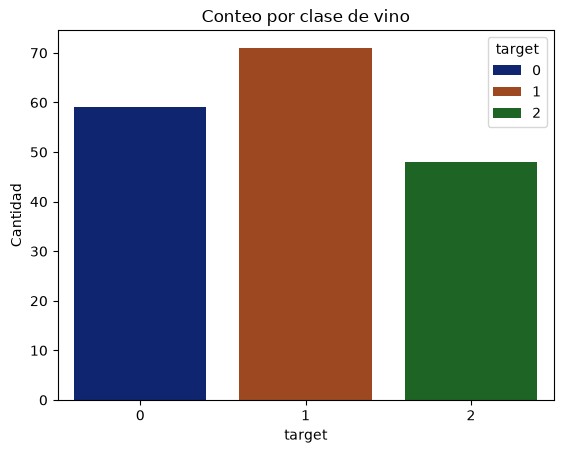

In [10]:
sns.countplot(data=df, x='target', hue="target", palette="dark")

plt.title('Conteo por clase de vino')
plt.xlabel('target')
plt.ylabel('Cantidad')
plt.show()

Se conocen que solo existen tres clases distintas de vino (0, 1, 2), que llega a ser util para los modelos

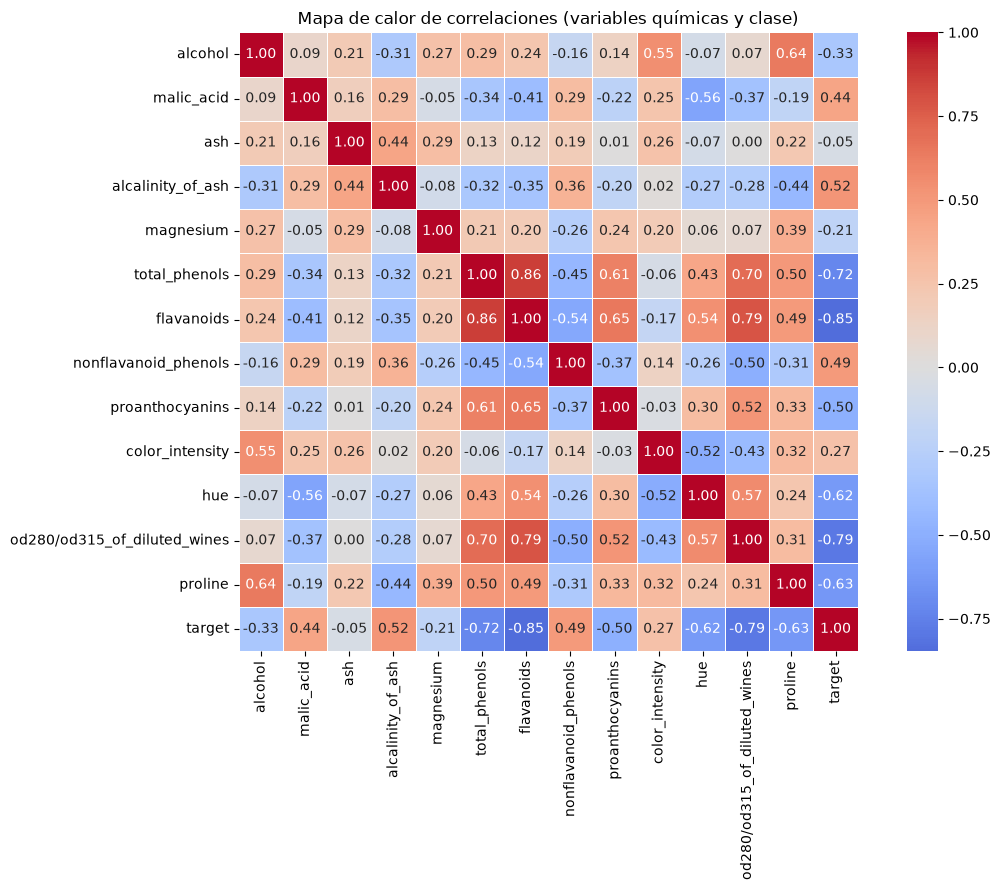

In [11]:
corr_matrix: pd.DataFrame = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Mapa de calor de correlaciones (variables químicas y clase)")
plt.tight_layout()
plt.show()

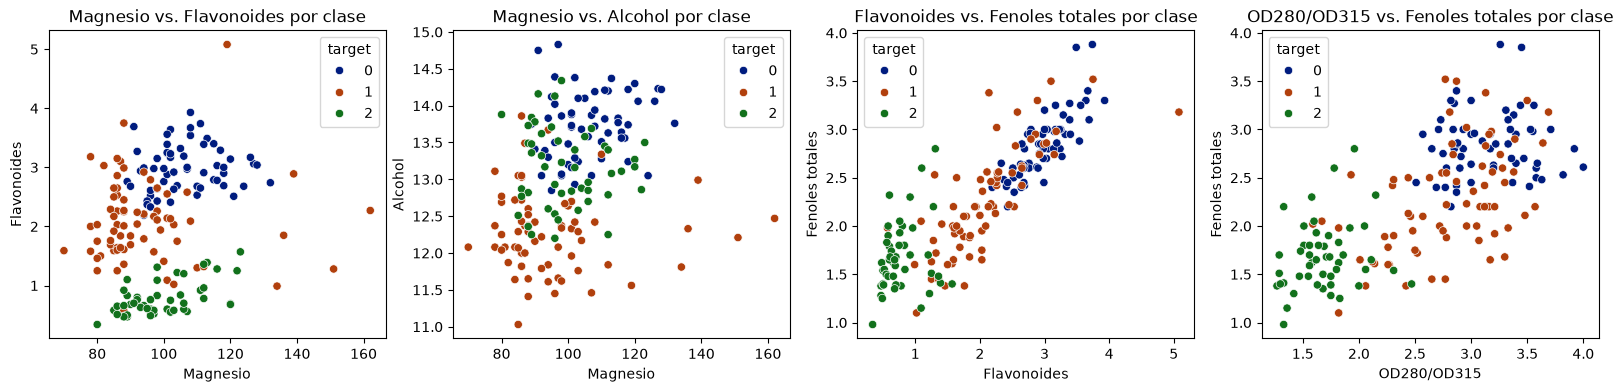

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.scatterplot(data=df, x="magnesium", y="flavanoids", hue="target", palette="dark", ax=axes[0])
axes[0].set_title("Magnesio vs. Flavonoides por clase")
axes[0].set_xlabel("Magnesio")
axes[0].set_ylabel("Flavonoides")

sns.scatterplot(data=df, x="magnesium", y="alcohol", hue="target", palette="dark", ax=axes[1])
axes[1].set_title("Magnesio vs. Alcohol por clase")
axes[1].set_xlabel("Magnesio")
axes[1].set_ylabel("Alcohol")

sns.scatterplot(data=df, x="flavanoids", y="total_phenols", hue="target", palette="dark", ax=axes[2])
axes[2].set_title("Flavonoides vs. Fenoles totales por clase")
axes[2].set_xlabel("Flavonoides")
axes[2].set_ylabel("Fenoles totales")

sns.scatterplot(data=df, x="od280/od315_of_diluted_wines", y="total_phenols", hue="target", palette="dark", ax=axes[3])
axes[3].set_title("OD280/OD315 vs. Fenoles totales por clase")
axes[3].set_xlabel("OD280/OD315")
axes[3].set_ylabel("Fenoles totales")

plt.show()

### Regresión logistica

In [14]:
# particion de train y test
from sklearn.model_selection import train_test_split
X: pd.DataFrame = df.drop(columns=["target"])
y: pd.Series = df["target"]

test_size: float = 0.29 #se decidió de manera empírica, ya que con 0.2 el model scrore daba 0.86
random_state: int = 41

# Partición
X_train: pd.DataFrame
X_test: pd.DataFrame
y_train: pd.Series
y_test: pd.Series
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

*-> Elaborado a partir del video de Ryan & Matt Data Science:* [`Enlace`](https://www.youtube.com/watch?v=aL21Y-u0SRs)

In [40]:
from sklearn.linear_model import LogisticRegression

model: LogisticRegression = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


/home/juampa-baquero/Code/Proyecto-Rapido-KNN-Regresor-Logistico/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipe = make_pipeline(StandardScaler(), LogisticRegression())
# Validación cruzada
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")

print(f"Scores por fold: {scores}")
print(f"Media CV: {scores.mean():.4f} (+/- {scores.std():.4f})")

Scores por fold: [0.96153846 1.         0.96       0.96       0.96      ]
Media CV: 0.9683 (+/- 0.0159)


In [16]:
y_pred = model.predict(X_test)

In [17]:
model.score(X_test, y_test)

0.9230769230769231

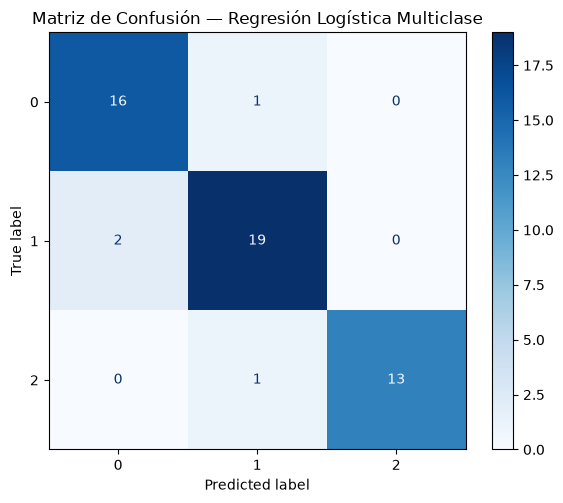

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm: np.ndarray = confusion_matrix(y_test, y_pred)
disp: ConfusionMatrixDisplay = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Matriz de Confusión — Regresión Logística Multiclase")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.94      0.91        17
           1       0.90      0.90      0.90        21
           2       1.00      0.93      0.96        14

    accuracy                           0.92        52
   macro avg       0.93      0.92      0.93        52
weighted avg       0.93      0.92      0.92        52



In [ ]:
#tabla resumen
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metricas_resumen: pd.DataFrame = pd.DataFrame({
  "accuracy": [accuracy_score(y_test, y_pred)],
  "precision": [precision_score(y_test, y_pred, average="weighted")],
  "recall": [recall_score(y_test, y_pred, average="weighted")],
  "f1": [f1_score(y_test, y_pred, average="weighted")]
})
print(metricas_resumen)

   accuracy  precision    recall        f1
0  0.923077   0.925214  0.923077  0.923545


# Ka ene ene

In [ ]:
from statistics import mode

In [35]:
# KNN - implementación personal

class KNN:
  x_ref: np.ndarray # Matriz 2D
  y_ref: np.ndarray # Target
  k: int

  def train(self, X_train: pd.DataFrame, y_train: pd.Series) -> None:
    # Como el algoritmo es mero flojo, se guarda el dataset entero xd
    self.x_ref: np.ndarray = X_train.to_numpy() # matriz
    self.y_ref: np.ndarray = y_train.to_numpy() # array

  def _distancia_euclidiana(self, x1: np.ndarray, x2: np.ndarray) -> float:
    return np.sqrt(np.sum((x1 - x2) ** 2))

  def predicciones(self, X_test: pd.DataFrame, k: int) -> np.ndarray:

    x_test: np.ndarray = X_test.to_numpy()
    
    predicciones: np.ndarray = np.zeros(len(x_test), dtype=int)
    for i in range(len(x_test)):
      distancias: list[tuple[float, int]] = []

      for x_act, y_act in zip(self.x_ref, self.y_ref):
        d: float = self._distancia_euclidiana(x_test[i], x_act)
        distancias.append((d, int(y_act)))

      distancias.sort()
      vecinos_cercanos: list[tuple[float, int]] = distancias[:k]

      targuets_vecinos: list[int] = [val for _, val in vecinos_cercanos]

      # Para mirar qué tan lejos está el centroide del vecino, tipo, el dato más alejado
      clase_ganadora: int = mode(targuets_vecinos) 
      predicciones[i] = clase_ganadora

    return predicciones

  def hacer_curva_errores(self, X_test: pd.DataFrame, y_test: pd.Series, max_k: int = 30) -> None:
    limite_k: int = min(max_k, len(self.x_ref))
    ks: list[int] = list(range(1, limite_k + 1))
    errores: list[float] = []
    y_true: np.ndarray = y_test.to_numpy()

    for k in ks:
      y_pred: np.ndarray = self.predicciones(X_test, k)
      tasa_error: float = float(np.mean(y_pred != y_true))
      errores.append(tasa_error)

    idx_mejor: int = int(np.argmin(errores))
    mejor_k: int = ks[idx_mejor]
    menor_error: float = errores[idx_mejor]
    self.k = mejor_k

    plt.figure(figsize=(10, 5))
    plt.plot(ks, errores, marker="o", linestyle="-", color="#2563eb", markersize=5, label="Error de validación")
    plt.axvline(mejor_k, color="#dc2626", linestyle="--", label=f"Mejor k = {mejor_k} (Error: {menor_error:.4f})")

    plt.title("Curva de Error vs. Número de Vecinos (K)")
    plt.xlabel("Valor de K")
    plt.ylabel("Tasa de Error (1 - Accuracy)")
    plt.xticks(range(1, limite_k + 1, max(1, limite_k // 15)))
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

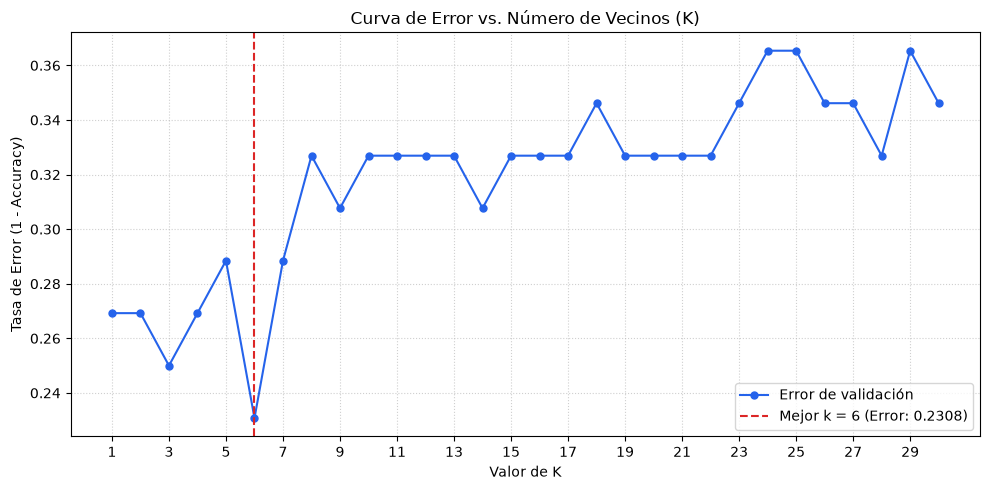

In [ ]:
# Implementación
knn: KNN = KNN()
knn.hacer_curva_errores(X_test, y_test)

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

knn.train(X_train, y_train)
y_pred: np.ndarray = knn.predicciones(X_test, 6)

print(f"Accuracy  -> {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision -> {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall    -> {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-Score  -> {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

Accuracy  -> 0.7692
Precision -> 0.7740
Recall    -> 0.7692
F1-Score  -> 0.7652
